# DoTime suites — overview

This notebook is the reference description of the two benchmark suites used in
the experiment. It answers, with executable checks, the questions that come up
repeatedly: what an episode contains, what the stored targets mean, how the
query point is located in time, and which episodes are usable.

Each section follows the same order:

1. **Explanation** — what the property is and why it matters for the probe.
2. **Code** — a short check against the released data.
3. **Reading the result** — how to interpret the output.

The suites in use are:

| Suite | Version | Role |
|---|---|---|
| `dot-Identifiability-v1` | 1.1.0 | eight named identification structures, single-step interventions |
| `dot-Continuous-v1` | 1.0.0 | interventions that last a finite window, used for duration effects |

The last section loads the superseded Identifiability **1.0.0** purely for the
historical record. It is never used in any analysis.

## 1. Setup

`ROOT` is the project root, whether the notebook is opened from the root or
from a `notebooks/` subfolder.

In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from huggingface_hub import snapshot_download
from dotime.benchmarks import load_benchmark

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

pd.set_option("display.width", 120)

/home/labian-3/Documentos/Fernanda/TSFMs/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Loading the two suites

Identifiability is pinned to an exact Hugging Face commit rather than just a
version string. A version tag can be re-pointed; a commit hash cannot, so this
is what makes the notebook reproducible months from now.

Continuous is loaded through the normal registry, since its frozen 1.0.0
release is unchanged.

In [2]:
IDENT_NAME = "dot-Identifiability-v1"
IDENT_VERSION = "1.1.0"
IDENT_COMMIT = "03e330504eeac298a0063c7c694a902a9fd0180d"

CONT_NAME = "dot-Continuous-v1"
CONT_VERSION = "1.0.0"

ident_dir = ROOT / "data" / f"{IDENT_NAME}-{IDENT_COMMIT[:8]}"

snapshot_download(
    repo_id="thummd/dot-Identifiability-v1",
    repo_type="dataset",
    revision=IDENT_COMMIT,
    local_dir=ident_dir,
)

Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 7907.39it/s]


'/home/labian-3/Documentos/Fernanda/TSFMs/data/dot-Identifiability-v1-03e33050'

In [3]:
from dataclasses import replace
from dotime.benchmarks import _SUITE_REGISTRY, _parse_suite_dir

ident_meta = replace(_SUITE_REGISTRY[IDENT_NAME], version=IDENT_VERSION)
ident = _parse_suite_dir(ident_meta, ident_dir)

cont = load_benchmark(CONT_NAME, version=CONT_VERSION)

print(f"Identifiability {IDENT_VERSION}: {len(ident)} episodes")
print(f"Continuous      {CONT_VERSION}: {len(cont)} episodes")

Identifiability 1.1.0: 10800 episodes
Continuous      1.0.0: 9999 episodes


> **Reading the result.** Both suites loaded. Identifiability has 10,800 episodes and Continuous 9,999.
Any different count means a different artifact was fetched — stop and check the
commit hash before running anything downstream.

## 2. What an episode contains

Every episode is a **pair of trajectories** simulated from the same causal
system: `x_obs` is what happened, `x_int` is what would have happened under
`do(A = v)`. Both are `(T, n_vars)` arrays.

The episode also stores where to look:

| Field | Meaning |
|---|---|
| `intervention.targets[0]` | which variable was intervened on (the treatment) |
| `intervention.times[0]` | the time step at which the intervention starts |
| `intervention.values` | the imposed do-value |
| `query_target` | which variable we are asked about (the outcome) |
| `query_time` | *normalised* time of the question, in [0, 1] |
| `y_true` | the answer: the interventional outcome at that point |

In [7]:
ep = ident[0]

print("structure       :", ep.structure)
print("x_obs shape     :", tuple(ep.x_obs.shape))
print("treatment var   :", int(ep.intervention.targets[0]))
print("intervention at :", int(ep.intervention.times[0]))
print("do-value        :", float(np.asarray(ep.intervention.values).reshape(-1)[0]))
print("queried var     :", int(ep.query_target[0]))
print("query_time      :", float(np.asarray(ep.query_time).reshape(-1)[0]))
print("metadata keys   :", list(ep.metadata.keys()))

structure       : bi_variate
x_obs shape     : (200, 2)
treatment var   : 0
intervention at : 73
do-value        : -3.4059526920318604
queried var     : 1
query_time      : 0.36500000953674316
metadata keys   : ['tier', 'diverged', 'pair_mode', 'y_causal_effect', 'y_oracle']


> **Reading the result.** One episode, printed field by field rather than dumping the 200x4 arrays.
Note that `query_time` is a fraction of the trajectory, not a step index — the
next section converts it. The metadata keys tell you which release you have:
1.1.0 adds `diverged` and `pair_mode` on top of `tier`, `y_causal_effect` and
`y_oracle`.

## 3. Helpers

Four small functions, used by everything below.

The one that deserves attention is `query_step`. The two suites scale
`query_time` differently — Identifiability by `T`, Continuous by `T - 1` — so a
single shared formula would silently read the wrong time step in one of them.
Section 4.3 verifies that this convention is the right one.

In [8]:
def to_numpy(x):
    # Episode fields are torch tensors; convert without assuming a device.
    if hasattr(x, "detach"):
        return x.detach().cpu().numpy()
    return np.asarray(x)


def scalar(x):
    # Read a single number out of a tensor, list or array.
    return float(to_numpy(x).reshape(-1)[0])


def query_step(ep, suite_name):
    # Turn the normalised query_time into an integer time index.
    length = int(ep.length)
    scale = length if suite_name == IDENT_NAME else length - 1
    return int(np.rint(scalar(ep.query_time) * scale))


def intervention_window(ep):
    # Continuous stores the start of the window but not its end. Under a HARD
    # intervention the treatment channel sits exactly at the do-value while the
    # window is active, so we walk forward until it stops.
    x_int = to_numpy(ep.x_int)
    treatment = int(ep.intervention.targets[0])
    start = int(ep.intervention.times[0])
    do_value = scalar(ep.intervention.values)

    end = start
    while end < len(x_int) and x_int[end, treatment] == do_value:
        end += 1
    return start, end

### One table per suite

Rather than writing a fresh loop for every question, we walk each suite once and
build a DataFrame. Every check after this is a one-line pandas expression.

In [9]:
def episode_table(suite, suite_name, with_window=False):
    rows = []
    for i, ep in enumerate(suite):
        x_obs, x_int = to_numpy(ep.x_obs), to_numpy(ep.x_int)
        t_start = int(ep.intervention.times[0])
        q = query_step(ep, suite_name)
        treatment = int(ep.intervention.targets[0])
        outcome = int(ep.query_target[0])

        row = {
            "episode": i,
            "structure": ep.structure,
            "n_vars": x_obs.shape[1],
            "t_start": t_start,
            "query_step": q,
            "offset": q - t_start,
            "treatment": treatment,
            "outcome": outcome,
            "self_intervention": treatment == outcome,
            "zeroed": bool(np.all(x_obs == 0) or np.all(x_int == 0)),
            "pre_onset_identical": np.array_equal(x_obs[:t_start], x_int[:t_start]),
            "y_true": scalar(ep.y_true),
            "interventional_level": float(x_int[q, outcome]),
            "paired_effect": float(x_int[q, outcome] - x_obs[q, outcome]),
            "stored_effect": scalar(ep.metadata["y_causal_effect"]),
        }

        if with_window:
            start, end = intervention_window(ep)
            row["duration"] = end - start
            row["in_window"] = start <= q < end

        rows.append(row)

    return pd.DataFrame(rows)


ident_df = episode_table(ident, IDENT_NAME)
cont_df = episode_table(cont, CONT_NAME, with_window=True)

print("Identifiability table:", ident_df.shape)
print("Continuous table     :", cont_df.shape)

Identifiability table: (10800, 15)
Continuous table     : (9999, 17)


> **Reading the result.** Two tables, one row per episode. Building them takes a minute or so on the full
suites; everything below reads from these instead of re-scanning.

# 4. Identifiability v1.1.0

## 4.1 Structures and balance

The suite covers eight named identification structures. They are not decoration:
each one changes what a correct answer requires. `back_door` needs adjustment on
an observed confounder, `front_door` routes through a mediator with the
confounder hidden, and `unobserved_confounder` is non-identifiable by design —
included to see how models degrade rather than to be solved.

In [10]:
display(ident_df["structure"].value_counts().sort_index().rename("episodes").to_frame())

,episodes
structure,
back_door,1350
bi_variate,1350
confounder_mediator,1350
front_door,1350
instrumental_variable,1350
mediator,1350
observed_confounder,1350
unobserved_confounder,1350


> **Reading the result.** Eight structures with an equal number of episodes each, so a pooled average
weights every structure the same. If you report a single number across the
suite, it is an unweighted mean over identification regimes of very different
difficulty — the per-structure breakdown is usually the more informative view.

## 4.2 Treatment and outcome pairs

Within a structure, is the causal question always the same pair of variables, or
does it move around? This matters because a per-structure average mixing several
treatment-outcome pairs would be averaging different questions.

In [11]:
display(
    ident_df.groupby(["structure", "treatment", "outcome"])
    .size()
    .rename("episodes")
    .reset_index()
)

,structure,treatment,outcome,episodes
0,back_door,0,2,1350
1,bi_variate,0,1,1350
2,confounder_mediator,0,3,1350
3,front_door,0,3,1350
4,instrumental_variable,0,3,1350
5,mediator,0,2,1350
6,observed_confounder,0,2,1350
7,unobserved_confounder,0,2,1350


> **Reading the result.** Each structure uses a single treatment-outcome pair, with the treatment always
at column 0. So a per-structure result is one well-defined causal question
repeated across many sampled systems, not a mixture.

## 4.3 Where the query sits in time

`query_time` is normalised, so it has to be converted to a step index. If the
conversion is wrong, every metric silently scores the wrong point in the
trajectory — this is the single most damaging thing that can go wrong.

There is a clean way to verify it. In this suite the question is asked at the
moment of intervention, so the recovered query step should equal `t_start`
exactly. If the formula were off by even one step, this check would fail.

In [12]:
print("offset value counts:")
print(ident_df["offset"].value_counts())

assert (ident_df["offset"] == 0).all(), "query_step formula does not match t_start"
print("\nPASS: query_step == t_start on every episode")

offset value counts:
offset
0    10800
Name: count, dtype: int64

PASS: query_step == t_start on every episode


> **Reading the result.** Every offset is zero, which confirms the `round(query_time * T)` convention for
this suite. It also fixes the forecast horizon: predicting from the intervention
onset up to and including the query is a **single step**.

## 4.4 What the stored targets mean

Two fields look like they could be the answer, and they are not the same thing:

- `y_true` — the interventional **level**, the value the outcome takes under the intervention.
- `metadata["y_causal_effect"]` — the **effect**, how much the intervention changed things.

The effect is a difference of two worlds: `x_int[q, Y] - x_obs[q, Y]`. The level
is just one world. Our primary metric scores effects, so reading the wrong field
would compare a difference against a level.

The check below compares each stored field against both candidates.

In [13]:
targets = pd.DataFrame({
    "y_true == interventional level": [
        np.isclose(ident_df["y_true"], ident_df["interventional_level"]).mean()
    ],
    "stored effect == paired difference": [
        np.isclose(ident_df["stored_effect"], ident_df["paired_effect"]).mean()
    ],
    "stored effect == interventional level": [
        np.isclose(ident_df["stored_effect"], ident_df["interventional_level"]).mean()
    ],
}, index=["fraction of episodes"]).T

display(targets)

,fraction of episodes
y_true == interventional level,1.0
stored effect == paired difference,1.0
stored effect == interventional level,0.0


> **Reading the result.** In 1.1.0 `y_true` is the interventional level and the stored effect is the
paired difference, as the names suggest. The third row is the one that matters
historically: in the superseded 1.0.0 release the stored effect matched the
*level* instead, which is exactly the bug section 7 documents.

In [14]:
# Null-effect episodes in Identifiability 1.1.0.
# The query sits at the intervention onset (offset 0, section 4.3), so any
# structure without a same-step path from treatment to outcome has a true
# effect of exactly zero at the query.
ident_df["null_exact"] = ident_df["stored_effect"] == 0
ident_df["null_tol"] = ident_df["stored_effect"].abs() <= 1e-9

null_by_structure = (
    ident_df.groupby("structure")[["null_exact", "null_tol"]]
    .sum()
    .assign(total=ident_df.groupby("structure").size())
)
null_by_structure["null_fraction"] = (
    null_by_structure["null_tol"] / null_by_structure["total"]
)
display(null_by_structure)

print("Null episodes (exact):    ", int(ident_df["null_exact"].sum()))
print("Null episodes (tolerance):", int(ident_df["null_tol"].sum()))
print("Nonzero-effect episodes:  ", int((~ident_df["null_tol"]).sum()))

,null_exact,null_tol,total,null_fraction
structure,,,,
back_door,259,259,1350,0.191852
bi_variate,204,204,1350,0.151111
confounder_mediator,459,459,1350,0.340000
front_door,452,452,1350,0.334815
instrumental_variable,211,211,1350,0.156296
mediator,1350,1350,1350,1.000000
observed_confounder,1350,1350,1350,1.000000
unobserved_confounder,1350,1350,1350,1.000000


Null episodes (exact):     5635
Null episodes (tolerance): 5635
Nonzero-effect episodes:   5165


## 4.5 Paired histories before the intervention

`x_obs` and `x_int` come from the same system with the same noise realisation,
so before the intervention starts nothing distinguishes them. They should be
identical, value for value.

This is what makes the effect meaningful: because everything else is shared, the
difference at the query point is attributable to the intervention alone. It is
also what lets P0 and P1 share a single context window.

In [15]:
print("Pre-onset identical:", int(ident_df["pre_onset_identical"].sum()), "/", len(ident_df))

Pre-onset identical: 10800 / 10800


> **Reading the result.** All episodes agree exactly before the onset. This is the property that failed in
the 1.0.0 release, where `x_obs` was shipped with its columns in a different
order from `x_int`.

## 4.6 Degenerate episodes

Some simulated systems blow up numerically. The generator detects this and
replaces the whole trajectory with zeros, so a degenerate episode is not noisy
data — it is a placeholder with no information at all.

Release 1.1.0 marks these with a `diverged` flag. We check both the flag and the
trajectories directly, since the two should agree.

In [16]:
n_diverged = sum(bool(ep.metadata["diverged"]) for ep in ident)

print("flagged as diverged :", n_diverged)
print("all-zero trajectories:", int(ident_df["zeroed"].sum()))

flagged as diverged : 0
all-zero trajectories: 0


> **Reading the result.** Both counts should tell the same story. Any episode that is zeroed has to be
dropped before analysis: its effect is zero by construction, so leaving it in
would hand every model a free correct answer on a question that was never asked.

## 4.7 Hidden variables

Three structures depend on a variable being **unobservable**: `front_door`,
`instrumental_variable` and `unobserved_confounder`. The whole point of
`unobserved_confounder`, for instance, is that the confounder cannot be adjusted
for — if a model could see it, the structure would be a different, easier
problem.

The generator hides it by zeroing that column in `x_obs`. The check below looks
at which columns are entirely zero, per structure.

In [17]:
hidden_cols = {}

for structure in sorted(ident_df["structure"].unique()):
    idx = ident_df.index[ident_df["structure"] == structure]
    patterns = Counter(
        tuple(np.where(np.all(to_numpy(ident[int(i)].x_obs) == 0, axis=0))[0].tolist())
        for i in idx
    )
    hidden_cols[structure] = patterns.most_common(2)

for structure, patterns in hidden_cols.items():
    print(f"{structure:24} {patterns}")

back_door                [((), 1350)]
bi_variate               [((), 1350)]
confounder_mediator      [((), 1350)]
front_door               [((1,), 1350)]
instrumental_variable    [((1,), 1350)]
mediator                 [((), 1350)]
observed_confounder      [((), 1350)]
unobserved_confounder    [((1,), 1350)]


> **Reading the result.** The three structures with a hidden variable should show one consistently zeroed
column; the other five should show none. A structure that is supposed to hide a
variable but shows no zeroed column is leaking it, which changes what the
structure actually tests.

## 4.8 One episode, drawn

Dashed lines are the observational world, solid lines the interventional one,
and the vertical line marks the intervention.

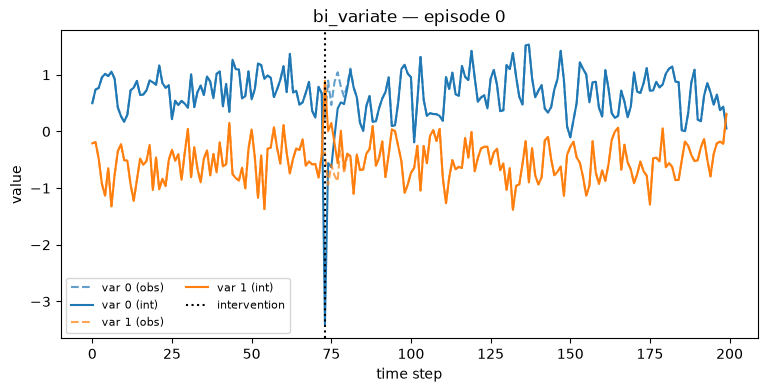

In [18]:
ep = ident[0]
x_obs, x_int = to_numpy(ep.x_obs), to_numpy(ep.x_int)
t_start = int(ep.intervention.times[0])

fig, ax = plt.subplots(figsize=(9, 4))
for j in range(x_obs.shape[1]):
    colour = f"C{j}"
    ax.plot(x_obs[:, j], linestyle="--", color=colour, alpha=0.7, label=f"var {j} (obs)")
    ax.plot(x_int[:, j], color=colour, label=f"var {j} (int)")

ax.axvline(t_start, color="black", linestyle=":", label="intervention")
ax.set_xlabel("time step")
ax.set_ylabel("value")
ax.set_title(f"{ep.structure} — episode 0")
ax.legend(ncol=2, fontsize=8)
plt.show()

> **Reading the result.** The two worlds overlap exactly on the left of the vertical line and separate
after it. That visual split is the pairing property from 4.5, and the vertical
gap at the query point is the quantity the probe is trying to predict.

# 5. Continuous v1.0.0

The difference from Identifiability is that the intervention **lasts a while**
instead of firing once. That is closer to how interventions work in practice —
a dose given for ten days, a policy active for a month — and it lets us ask
whether a predicted effect grows with the length of the intervention.

In [15]:
display(cont_df["structure"].value_counts().sort_index().rename("episodes").to_frame())
print("Total episodes:", len(cont_df))

,episodes
structure,
back_door,3333
front_door,3333
instrumental_variable,3333


Total episodes: 9999


> **Reading the result.** Three structures rather than eight, balanced. The structures present are a
subset of the Identifiability ones, so any comparison across the two suites is
restricted to those three.

## 5.1 Targets

The same check as 4.4. It is worth repeating per suite rather than assuming,
because identical field names have carried different meanings across releases.

In [16]:
print("y_true == interventional level     :",
      np.isclose(cont_df["y_true"], cont_df["interventional_level"]).mean())
print("stored effect == paired difference :",
      np.isclose(cont_df["stored_effect"], cont_df["paired_effect"]).mean())

y_true == interventional level     : 1.0
stored effect == paired difference : 1.0


> **Reading the result.** Continuous stores the paired difference as its effect, matching 1.1.0
Identifiability. The two suites can therefore share one effect definition.

## 5.2 Recovering the intervention window

The episode records when the intervention **starts** but not when it ends. The
end is recoverable from the data: under a HARD intervention the treatment
variable is pinned to the do-value for as long as the window is active, so we
walk forward until it stops matching.

That is what `intervention_window()` does, and the duration column already
carries the result.

,duration (steps)
count,9999.000000
mean,39.811581
std,11.492559
min,20.000000
25%,30.000000
50%,40.000000
75%,50.000000
max,60.000000


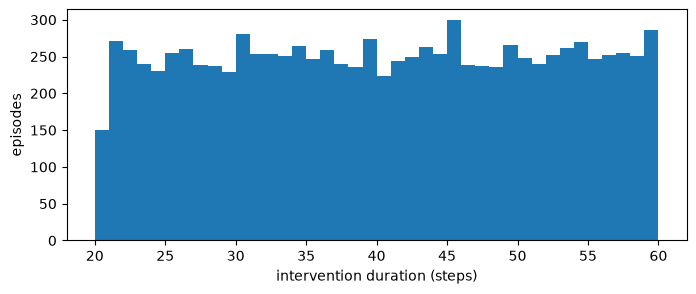

In [17]:
display(cont_df["duration"].describe().to_frame("duration (steps)"))

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(cont_df["duration"], bins=40)
ax.set_xlabel("intervention duration (steps)")
ax.set_ylabel("episodes")
plt.show()

> **Reading the result.** Durations vary continuously rather than taking a handful of fixed values, so
they can be used as a regressor for duration-accrual analysis instead of being
binned. Note the range is fairly narrow, which limits how much accrual can be
detected.

## 5.3 When is the question asked?

Two things vary independently in this suite: how long the intervention lasts,
and how long after its start the question is asked. Both influence the true
effect, so they need to be looked at together rather than one at a time.

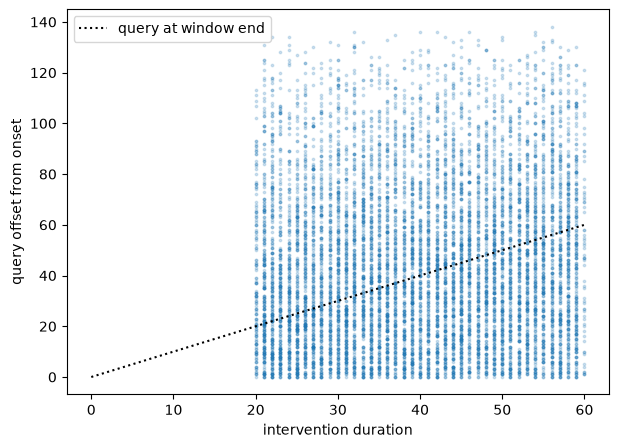

offset range: 0 to 138


In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(cont_df["duration"], cont_df["offset"], s=3, alpha=0.2)
ax.plot([0, cont_df["duration"].max()], [0, cont_df["duration"].max()],
        color="black", linestyle=":", label="query at window end")
ax.set_xlabel("intervention duration")
ax.set_ylabel("query offset from onset")
ax.legend()
plt.show()

print("offset range:", int(cont_df["offset"].min()), "to", int(cont_df["offset"].max()))

> **Reading the result.** Points below the dotted line are queried while the intervention is still
running; points above it are queried after it ended. The spread on the vertical
axis is much wider than the spread of durations, which is why a duration-accrual
plot that ignores the offset would confound accrual with the natural decay of an
effect over time.

## 5.4 The four groups

Two binary properties split the suite into groups that behave very differently:

- **in-window vs post-window** — was the intervention still active when the question was asked?
- **self vs non-self** — is the queried variable the one being intervened on?

A self-intervention query while the window is active is not really a causal
question: the answer is the do-value, because that variable is being held there.
Those episodes measure whether the interface copies a value, not whether the
model propagates an effect.

In [19]:
groups = (
    cont_df.groupby(["in_window", "self_intervention"])
    .size()
    .rename("episodes")
    .reset_index()
)
display(groups)

,in_window,self_intervention,episodes
0,False,False,3333
1,False,True,1738
2,True,False,3267
3,True,True,1661


> **Reading the result.** All four groups are substantial. The primary analysis uses **in-window,
non-self** only: the treatment path is fully known up to the query, and the
question is about propagation to a different variable. Post-window episodes need
a different protocol, because the treatment's future is unknown after the window
ends.

In [20]:
primary = cont_df[cont_df["in_window"] & ~cont_df["self_intervention"]]

display(primary["structure"].value_counts().sort_index().rename("episodes").to_frame())
print("Primary subset:", len(primary), "episodes")
print("Horizon from onset to query:", int(primary["offset"].min() + 1),
      "to", int(primary["offset"].max() + 1))

,episodes
structure,
back_door,1051
front_door,1069
instrumental_variable,1147


Primary subset: 3267 episodes
Horizon from onset to query: 1 to 59


> **Reading the result.** The primary subset keeps all three structures, though not perfectly balanced, so
a stratified sample should be capped by the smallest structure. The horizon
range matters for models with patch-based decoding: a model whose conditioning
only takes effect after N steps cannot be scored on horizons shorter than N.

# 6. Side-by-side summary

The properties that determine how each suite has to be handled.

In [21]:
summary = pd.DataFrame({
    f"Identifiability {IDENT_VERSION}": {
        "episodes": len(ident_df),
        "structures": ident_df["structure"].nunique(),
        "trajectory length": int(ident[0].length),
        "intervention": "single step",
        "query_time scale": "T",
        "query offset": "always 0",
        "forecast horizon": "1",
        "self-intervention episodes": int(ident_df["self_intervention"].sum()),
        "zeroed episodes": int(ident_df["zeroed"].sum()),
    },
    f"Continuous {CONT_VERSION}": {
        "episodes": len(cont_df),
        "structures": cont_df["structure"].nunique(),
        "trajectory length": int(cont[0].length),
        "intervention": "window of 20-60 steps",
        "query_time scale": "T - 1",
        "query offset": f"{int(cont_df['offset'].min())} to {int(cont_df['offset'].max())}",
        "forecast horizon": "variable",
        "self-intervention episodes": int(cont_df["self_intervention"].sum()),
        "zeroed episodes": int(cont_df["zeroed"].sum()),
    },
})

display(summary)

,Identifiability 1.1.0,Continuous 1.0.0
episodes,10800,9999
structures,8,3
trajectory length,200,200
intervention,single step,window of 20-60 steps
query_time scale,T,T - 1
query offset,always 0,0 to 138
forecast horizon,1,variable
self-intervention episodes,0,3399
zeroed episodes,0,0


> **Reading the result.** The two rows that most often cause bugs are the `query_time` scale, which is
different between the suites, and the forecast horizon, which is fixed at 1 in
one suite and variable in the other. Any code shared between them has to branch
on the suite name rather than assume.

# 7. Historical record — the superseded Identifiability 1.0.0

**This section is the only place the old release is loaded, and it is used in no
analysis.** It exists so the reasons for migrating to 1.1.0 stay reproducible
rather than living in a conversation.

The released 1.0.0 artifact had three documented problems, all on the
observational side:

1. `x_obs` was stored with its columns in a different order from `x_int`, so an
   index taken from the episode metadata read a different variable in each.
2. Hidden variables were not masked in the released `x_obs`, so structures that
   depend on a variable being invisible leaked it.
3. `metadata["y_causal_effect"]` was computed against a masked observational
   trajectory, which is zero after the intervention, collapsing the stored
   "effect" into the interventional level.

In [22]:
ident_old = load_benchmark(IDENT_NAME, version="1.0.0")
old_df = episode_table(ident_old, IDENT_NAME)

print("Old episodes:", len(old_df))
print("Old metadata keys:", sorted(ident_old[0].metadata.keys()))
print("New metadata keys:", sorted(ident[0].metadata.keys()))

Old episodes: 10800
Old metadata keys: ['tier', 'y_causal_effect', 'y_oracle']
New metadata keys: ['diverged', 'pair_mode', 'tier', 'y_causal_effect', 'y_oracle']


> **Reading the result.** Same episode count. The metadata key sets differ: `diverged` and `pair_mode` are
new in 1.1.0, which is the quickest way to tell the two releases apart in code.

## 7.1 The three problems, measured

One comparison per problem, on both releases.

For the hidden-variable check, zeroed episodes are excluded — their columns are
all zero anyway, which would look like correct masking.

In [23]:
HIDDEN_STRUCTURES = {"front_door", "instrumental_variable", "unobserved_confounder"}


def hidden_masked_fraction(suite, table):
    # Among non-zeroed episodes of hidden-variable structures, how many have at
    # least one fully zeroed column in x_obs?
    mask = table["structure"].isin(HIDDEN_STRUCTURES) & ~table["zeroed"]
    idx = table.index[mask]
    if len(idx) == 0:
        return float("nan")
    masked = sum(
        np.any(np.all(to_numpy(suite[int(i)].x_obs) == 0, axis=0)) for i in idx
    )
    return masked / len(idx)


def release_properties(suite, table):
    return {
        "stored effect == paired difference":
            np.isclose(table["stored_effect"], table["paired_effect"]).mean(),
        "stored effect == interventional level":
            np.isclose(table["stored_effect"], table["interventional_level"]).mean(),
        "pre-onset histories identical":
            table["pre_onset_identical"].mean(),
        "hidden variable masked":
            hidden_masked_fraction(suite, table),
        "zeroed episodes":
            int(table["zeroed"].sum()),
    }


comparison = pd.DataFrame({
    "v1.0.0 (superseded)": release_properties(ident_old, old_df),
    "v1.1.0 (in use)": release_properties(ident, ident_df),
})

display(comparison)

,v1.0.0 (superseded),v1.1.0 (in use)
stored effect == paired difference,0.046389,1.0
stored effect == interventional level,1.000000,0.0
pre-onset histories identical,0.046019,1.0
hidden variable masked,0.000000,1.0
zeroed episodes,504.000000,0.0


> **Reading the result.** Read the first three rows as fractions of episodes. In 1.0.0 the stored effect
matches the interventional level instead of the paired difference, the
pre-onset histories do not agree, and the hidden columns are not masked — the
three documented problems, each visible as a number. In 1.1.0 all three
properties hold.

## 7.2 Why this is kept

The 1.0.0 release is a frozen, citable artifact and was not modified in place —
that is correct practice, since silently changing a published dataset would
break anyone who had already reported results on it. The fixes went into a new
version instead.

The practical consequences for this project:

- results are reported against **1.1.0**, pinned to the commit in section 1;
- any number produced against 1.0.0 before the migration is not comparable and
  was discarded;
- published baseline numbers computed on 1.0.0 carry the same issues, so
  comparisons to them are made on the interventional level, which was unaffected,
  rather than on the effect.